# Task 4 · Reconstruct the Flight (20 marks)

Connect your trackers to the provided pipeline and recover the lander's
velocity and 3D trajectory, then find out how the quality of your optical flow
decides the result. You write only the four short functions of Task 4.1; the
camera-motion fit (`provided/task4/motion_model.py`), the flight code
(`provided/task4/trajectory.py`) and the plots are provided.

The camera points straight down at flat ground. As the lander moves, the
tracked ground features between two consecutive frames undergo a similarity:
they scale, rotate and translate,

$$
\mathbf{x}_{k+1} = s_k R(\theta_k)\,\mathbf{x}_k + \mathbf{t}_k,
\qquad s_k = \frac{Z_k}{Z_{k+1}}.
$$

The provided fit estimates $s_k$, $\theta_k$ and $\mathbf{t}_k$ by robust least
squares, and the flight code turns them into altitude, position, velocity and
the 3D trajectory, in metres and seconds. The world frame is fixed to frame
270: $X$ to the right, $Y$ toward its top (image $y$ points down), $Z$ the
altitude (up).

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

In [1]:
# PROVIDED: run this cell first (save task3.ipynb before)
%matplotlib inline
import numpy as np
from provided.notebook import check, use_my_functions
from provided.sift import sift_matches, track_with_sift
from provided.task4.compare_trackers import compare
from provided.task4.run import read_motion, reconstruct_flight

use_my_functions(3)               # your Task 1 to 3 functions, from the saved notebooks

your functions from task1.ipynb, task2.ipynb, task3.ipynb (the saved files): spatial_gradients, temporal_difference, structure_tensor, feature_score, select_features, lucas_kanade_update, one_step_flow, track_point, track_points


## 4.1 Connect your trackers to the pipeline (4 marks)

Fill in the three adapters `one_step`, `iterative` and `sift_guided`, which
call your Task 3 `track_points`, and `track_pair`, which selects points
(Task 1.3), runs one tracker and keeps the valid tracks. A tracker is a
function `(image0, image1, points) -> (tracked, valid)`.

In [2]:
# YOUR CODE: Task 4.1

# the settings every tracker uses (keep them for the reference numbers)
MAX_POINTS = 200
FEATURE_RADIUS = 3
MIN_DISTANCE = 10
TRACK_RADIUS = 7
ITERATIONS = 10

def one_step(image0, image1, points):
    """One Lucas-Kanade update per point (the Task 2 method)."""
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=1)


def iterative(image0, image1, points):
    """Iterative Lucas-Kanade per point (Task 3)."""
    return track_points(image0, image1, points, TRACK_RADIUS, max_iterations=ITERATIONS)


def sift_guided(image0, image1, points):
    """Iterative Lucas-Kanade started from SIFT guesses (Task 3.3)."""
    matches = sift_matches(image0, image1)
    return track_with_sift(track_points, image0, image1, points, matches, TRACK_RADIUS,
                           max_iterations=ITERATIONS)


def track_pair(image0, image1, tracker):
    """Select points in image0 and track them into image1 with `tracker`.

    Returns (points0, points1), keeping only the valid tracks.
    """
    points = select_features(image0, MAX_POINTS, FEATURE_RADIUS, MIN_DISTANCE)
    tracked, valid = tracker(image0, image1, points)
    valid = np.asarray(valid, dtype=bool)
    return points[valid], np.asarray(tracked)[valid]

In [3]:
check("4.1")

trackers = {"one-step": one_step, "iterative": iterative, "sift-guided": sift_guided}

Task 4.1 checks
  PASS  one step tracks a small shift
  PASS  iterative tracks a larger shift


  PASS  sift guided beats one step on large motion
  PASS  track pair selects and tracks points
4 of 4 passed


**(a)** Why must `track_pair` drop the failed tracks before the motion fit?

*TODO*

## 4.2 Read the motion from the images (4 marks)

The provided cell tracks all 143 frame pairs with your SIFT-guided tracker
(a few minutes), fits the camera motion of every pair and plots the zoom,
rotation and shift.

tracking 143 pairs with the sift-guided tracker (a few minutes)


  the first pair took 3.6 s, so all 143 pairs take about 9 minutes. If your select_features loops over every pixel, the speed tip in its docstring makes it much faster.
  270 to 271: 178 tracks


  290 to 291: 166 tracks


  310 to 311: 171 tracks


  330 to 331: 193 tracks


...

  370 to 371: 178 tracks


  390 to 391: 171 tracks


  410 to 411: 152 tracks


  412 to 413: 136 tracks
  saved outputs/task4/motion.csv (143 pairs)


  saved outputs/task4/zoom.png


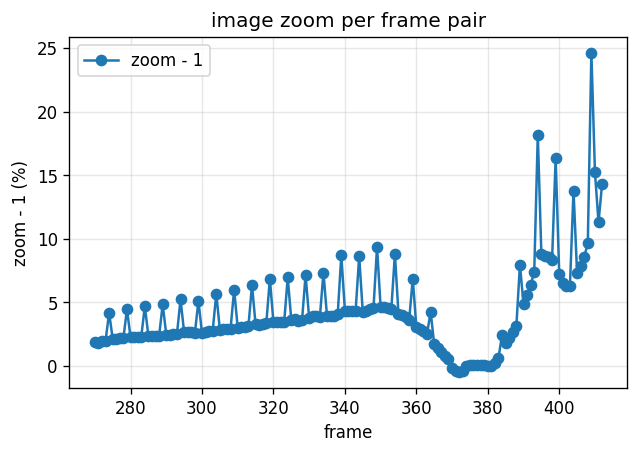

  saved outputs/task4/rotation.png


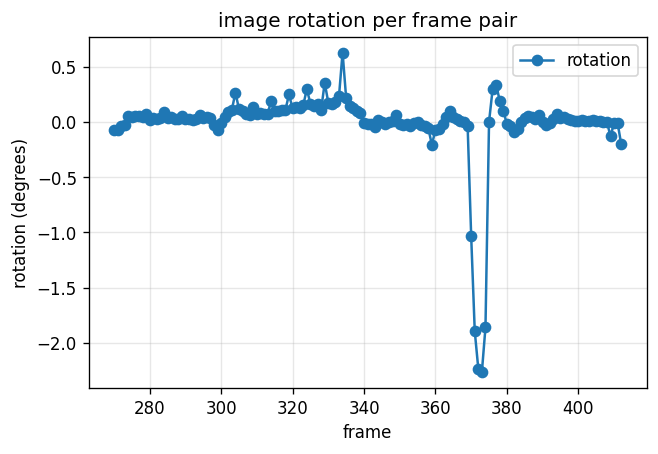

  saved outputs/task4/shift.png


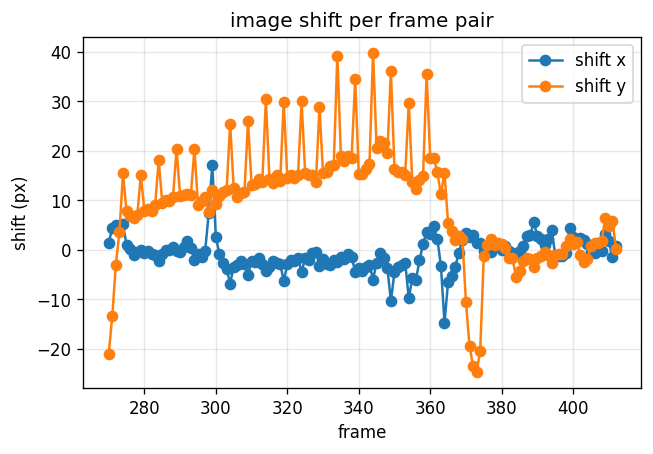

In [4]:
motion = read_motion(track_pair, trackers["sift-guided"])

**(a)** Why is the zoom $s_k = Z_k / Z_{k+1}$? Use the pinhole model.

*TODO*

**(b)** What are the phases of the descent, and at about which frames do they change?

*TODO*

**(c)** Which pattern in these plots is not caused by the lander, and how can you tell?

*TODO*

## 4.3 Reconstruct the flight (4 marks)

The provided cell turns the motion into the altitude, the velocity
$(v_X, v_Y, v_Z)$, the time to touchdown $\tau = Z / (-v_Z)$, the 3D trajectory
and the ground track (seen from above, $X$ to the right and $Y$ up).

  saved outputs/task4/altitude.png


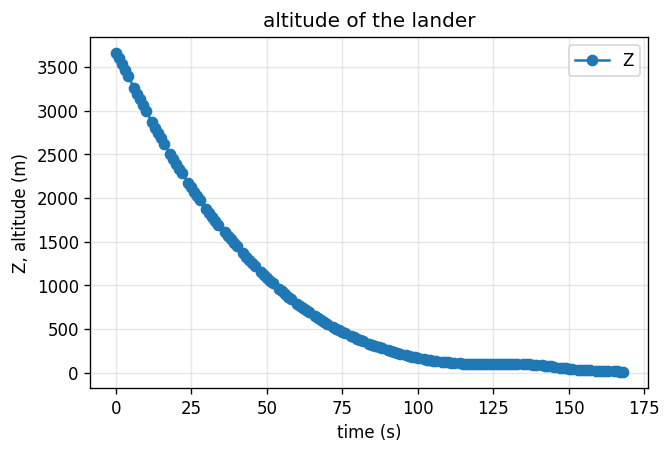

  saved outputs/task4/velocity.png


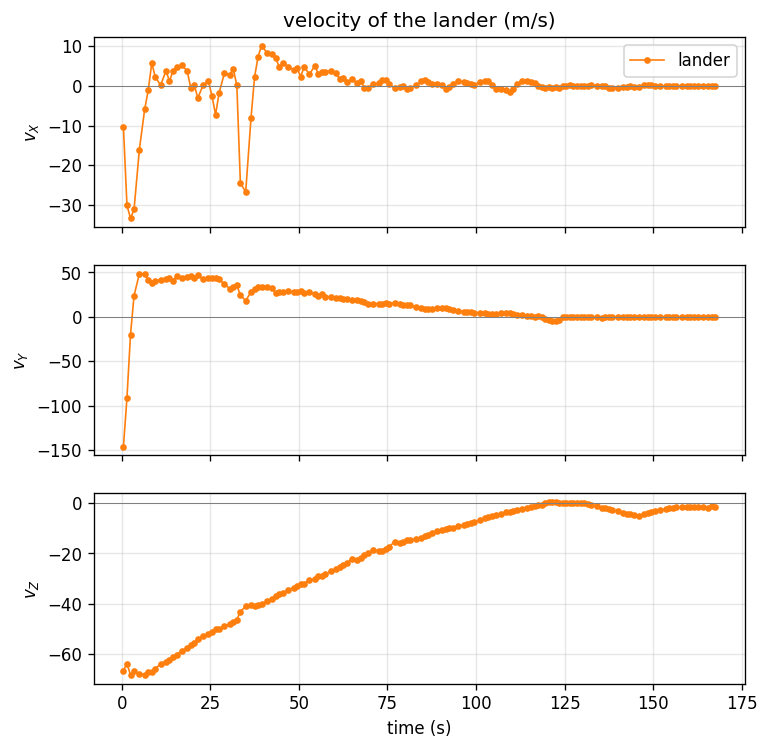

  saved outputs/task4/time_to_touchdown.png


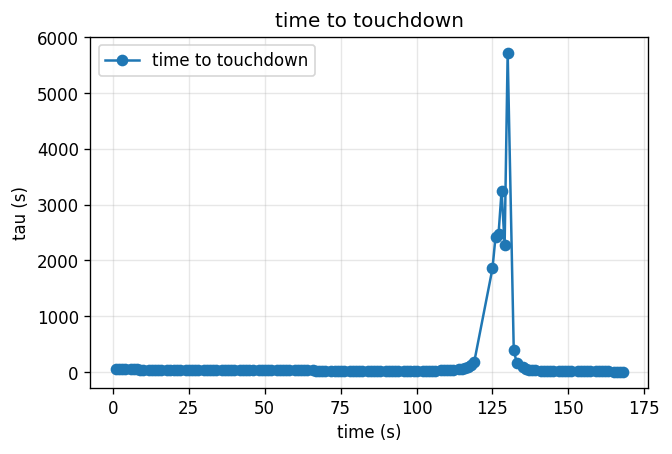

  saved outputs/task4/trajectory_3d.png


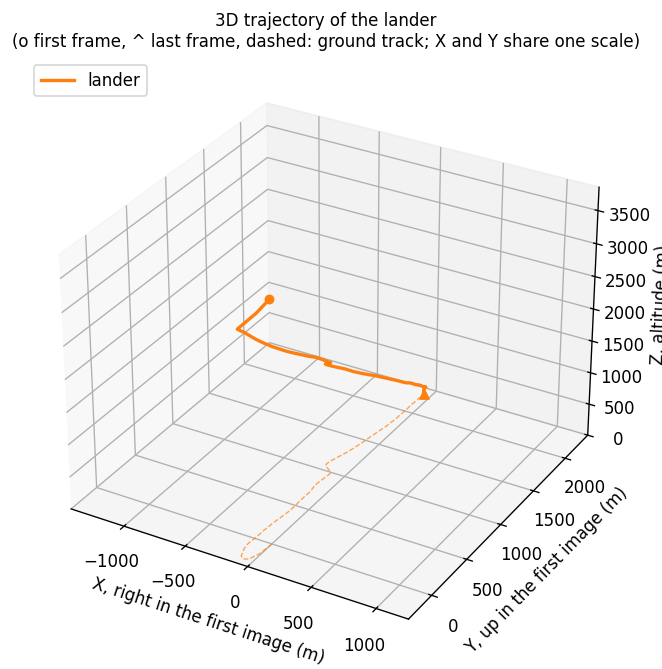

  saved outputs/task4/ground_track.png


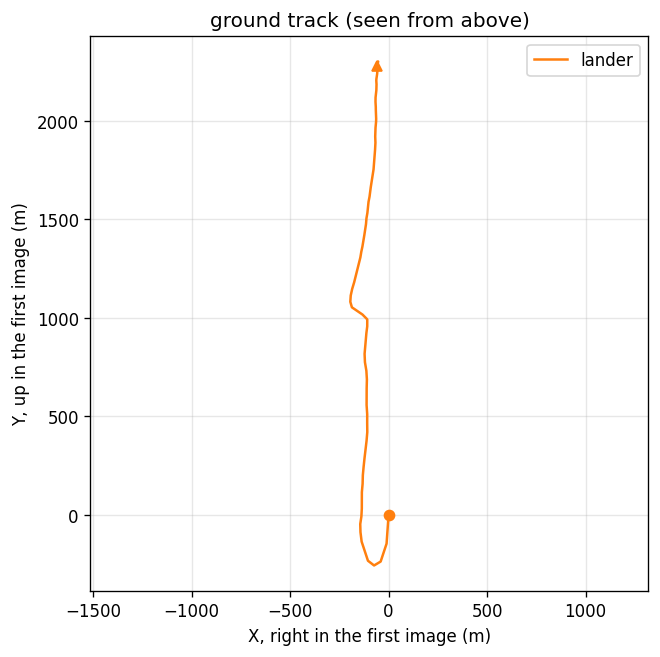

  saved outputs/task4/summary.json
  summary: frames [270, 413], length_unit m, time_unit s, start_Z 3667, end_Z 9.112, duration 168, horizontal_drift 2280, max_descent_speed 68.38


In [5]:
flight, summary = reconstruct_flight(motion)

**Table.** Fill in the numbers printed above (also in `outputs/task4/summary.json`).

| Quantity | Value |
|----------|-------|
| Start and end altitude Z | *TODO* |
| Duration | *TODO* |
| Largest descent speed | *TODO* |
| Horizontal drift | *TODO* |

**(a)** Which result do you trust least, and why?

*TODO*

## 4.4 Compare the three trajectories (5 marks)

The provided cell runs the whole pipeline once per tracker on the same points
and draws the three ground tracks together (several minutes the first time;
the tracks are saved and reused while your code stays the same).

tracking 143 pairs with 3 trackers (several minutes)


  the first pair took 4.9 s, so all 143 pairs take about 12 minutes. If your select_features loops over every pixel, the speed tip in its docstring makes it much faster.
  270 to 271: tracks kept: one-step 186, iterative 185, sift-guided 178


  290 to 291: tracks kept: one-step 184, iterative 181, sift-guided 166


  310 to 311: tracks kept: one-step 186, iterative 186, sift-guided 171


  330 to 331: tracks kept: one-step 196, iterative 196, sift-guided 193


...

  370 to 371: tracks kept: one-step 184, iterative 184, sift-guided 178


  390 to 391: tracks kept: one-step 187, iterative 187, sift-guided 171


  410 to 411: tracks kept: one-step 189, iterative 189, sift-guided 152


  412 to 413: tracks kept: one-step 191, iterative 191, sift-guided 136


  saved outputs/task4/compare/ground_track.png


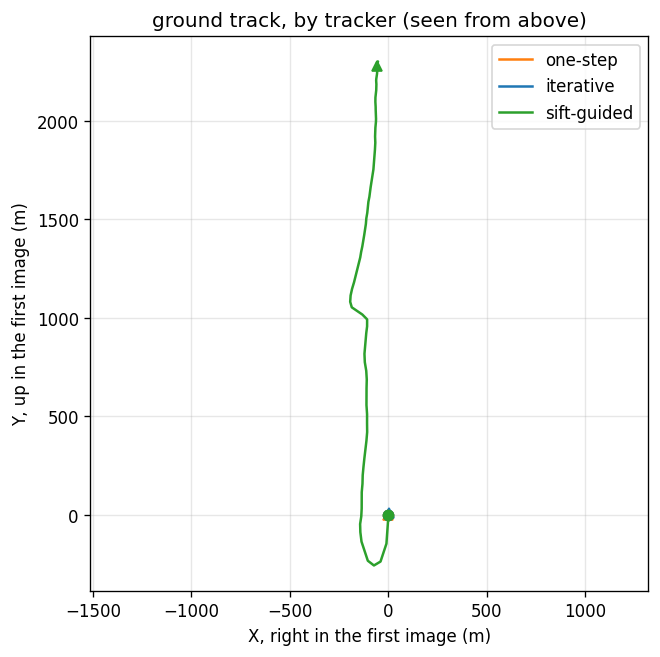

  saved outputs/task4/compare/summary.csv
      one-step: end Z 99 m, drift 1.299 m, median residual 0.23 px
     iterative: end Z 92.87 m, drift 8.802 m, median residual 1.79 px
   sift-guided: end Z 9.112 m, drift 2280 m, median residual 0.35 px


In [6]:
table = compare(trackers, track_pair)

**Table.** Fill in the numbers printed above (also in `outputs/task4/compare/summary.csv`).

| Tracker | End altitude | Horizontal drift | Median residual |
|---------|--------------|------------------|-----------------|
| one-step | *TODO* | *TODO* | *TODO* |
| iterative | *TODO* | *TODO* | *TODO* |
| SIFT-guided | *TODO* | *TODO* | *TODO* |

**(a)** Which trajectory do you trust, and which Task 3 result supports it?

*TODO*

**(b)** Does a low median residual mean a tracker is right? Use your numbers.

*TODO*

Optional, not graded: the next cell writes
`outputs/task4/trajectory_animation.html`, the three flights as an interactive
3D animation to open in a web browser.

In [7]:
from provided.task4.animate_trajectory import main as animate
animate([])

  saved /home/claude/project/outputs/task4/trajectory_animation.html  (open it in a web browser)
done


## 4.5 Where does uncertainty come from? (3 marks)

**(a)** Why does a small error in each zoom grow along the descent?

*TODO*

**(b)** What changes if the anchor altitude is 10 % too high? And if the focal length is?

*TODO*

# Final Mission Report · What Did We Learn? (bonus, 5 marks)

One or two sentences each, with one piece of evidence from your results.

**Q1.** Where in the descent does "all pixels in a window move together" fail most, and what in your results shows it?

*TODO*

**Q2.** Would a pyramidal (coarse-to-fine) KLT tracker fix 300 to 301? Would it fix 409 to 410? Why?

*TODO*

**Q3.** If you ignored the pattern from Task 4.2, which Task 4.3 results would be wrong, and by how much?

*TODO*

**Q4.** Where does the "flat ground, camera straight down" model fail, and what error does it cause?

*TODO*

**Q5.** Name one independent measurement that would check your trajectory, and what it would check.

*TODO*

# References

List every source you used, including the Chang'e-5 landing camera data (level 2A, https://moon.bao.ac.cn).

*TODO*